# Chapter 15: Introduction to Convolutional Neural Networks

## Learning Objectives

This chapter introduces Convolutional Neural Networks (CNNs), which are commonly used for image processing and classification.

The objectives are:
1. Understand the basic structure of a CNN.
2. Load and preprocess image data.
3. Build a simple CNN using PyTorch.
4. Train the CNN for image classification.
5. Evaluate classification performance.

## 1. Convolutional Neural Networks

A Convolutional Neural Network is a neural network architecture designed to process grid-like data, especially images.

Important CNN components include:

- Convolutional layer: extracts local patterns such as edges and textures.
- Activation function: introduces nonlinearity.
- Pooling layer: reduces spatial dimensions.
- Fully connected layer: combines learned features to produce predictions.

CNNs use shared convolutional filters, allowing them to detect patterns in different image locations with fewer parameters than a fully connected network operating directly on every pixel.

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(42)

# Convert images to tensors and normalize pixel values
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Download and load the FashionMNIST dataset
train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 60000
Testing samples: 10000


In [5]:
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

# Inspect one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


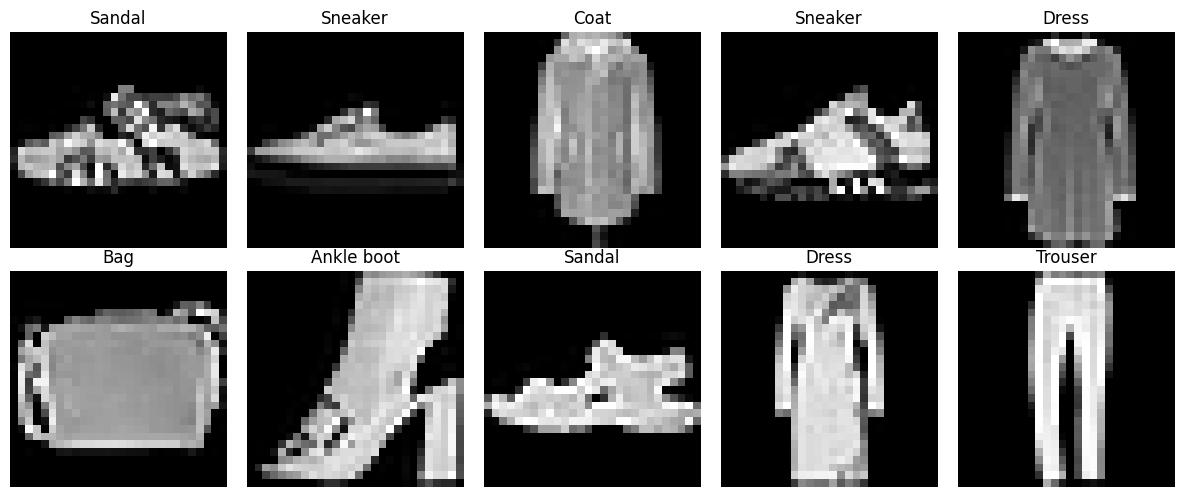

In [6]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = images[i].squeeze().numpy()

    # Undo normalization for display
    image = image * 0.5 + 0.5

    ax.imshow(image, cmap="gray")
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Input shape: (batch, 1, 28, 28)
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Shape after pooling: (batch, 16, 14, 14)
            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)

            # Shape after pooling: (batch, 32, 7, 7)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = SimpleCNN().to(device)

print("Device:", device)
print(model)

Device: cpu
SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 2. Understanding the CNN Architecture

The first convolutional layer transforms one input channel into 16 feature maps. ReLU introduces nonlinearity, and max pooling reduces the image dimensions.

The second convolutional layer produces 32 feature maps. After the second pooling operation, the feature maps have dimensions of 32 × 7 × 7.

The `Flatten` layer converts the feature maps into a vector. Fully connected layers then use this vector to produce 10 output scores, one for each FashionMNIST class.

The output values are logits. Cross-entropy loss can use these logits directly without applying softmax in the model.

In [8]:
loss_function = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", loss_function)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [9]:
epochs = 3
train_loss_history = []

for epoch in range(epochs):
    model.train()

    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = loss_function(outputs, labels)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    train_loss_history.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"| Training Loss: {epoch_loss:.4f}"
    )

Epoch 1/3 | Training Loss: 0.4768
Epoch 2/3 | Training Loss: 0.3142
Epoch 3/3 | Training Loss: 0.2703


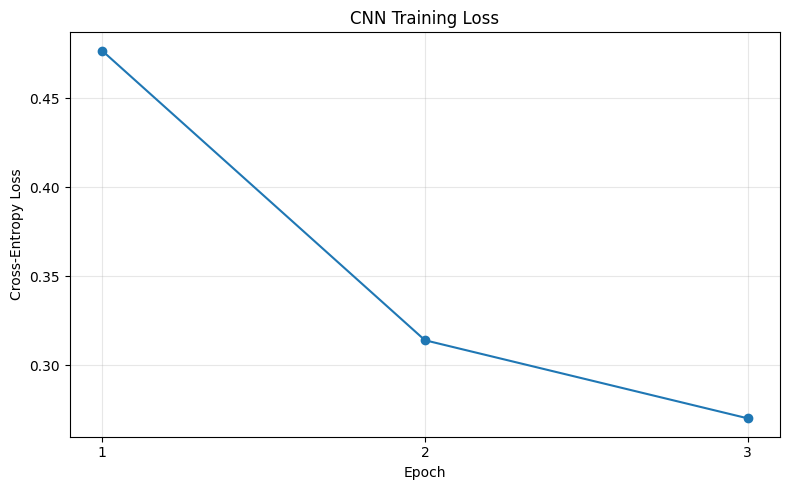

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    train_loss_history,
    marker="o"
)

plt.title("CNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        # Select the class with the highest logit
        predictions = torch.argmax(outputs, dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

test_accuracy = correct / total

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 0.8913
Test Accuracy: 89.13%


In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(10)),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.83      0.85      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.78      0.88      0.83      1000
       Dress       0.82      0.94      0.88      1000
        Coat       0.84      0.80      0.82      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.79      0.62      0.70      1000
     Sneaker       0.92      0.98      0.95      1000
         Bag       0.98      0.97      0.98      1000
  Ankle boot       0.99      0.93      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



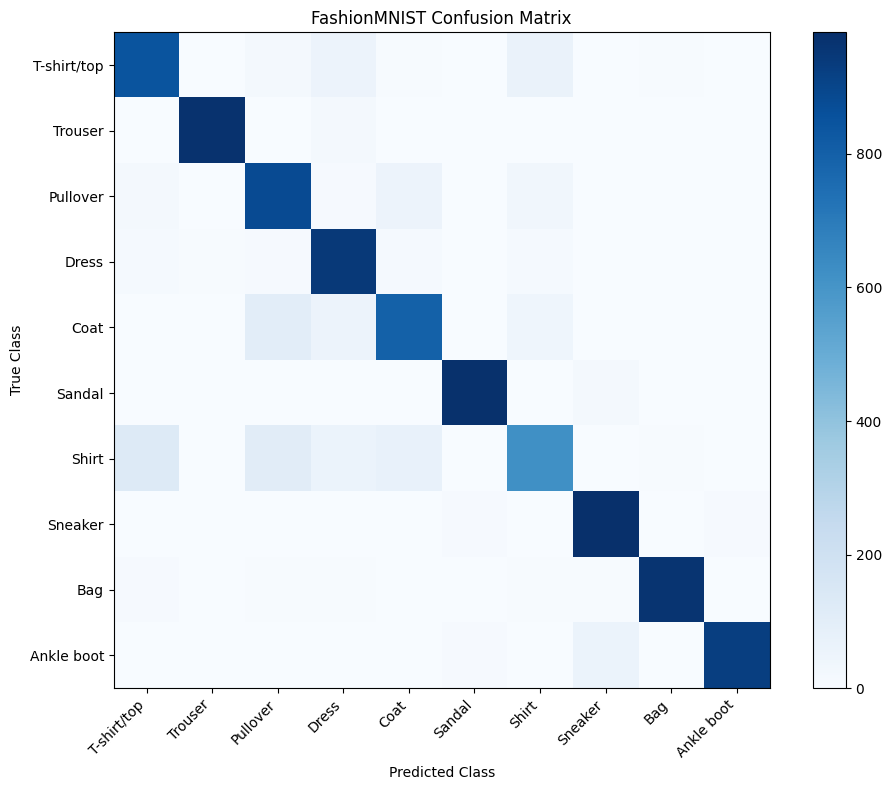

In [13]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("FashionMNIST Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
plt.colorbar()
plt.tight_layout()
plt.show()

## 3. Evaluating a CNN

Test accuracy measures the proportion of test images classified correctly.

A classification report provides precision, recall, and F1-score for each class. The confusion matrix shows which classes are frequently confused with one another.

Training loss indicates how well the model fits the training data. Test performance provides additional information about how well the model generalizes to unseen images.

The results depend on the model architecture, optimizer, learning rate, number of epochs, and other training choices. They may vary if the random seed or environment changes.

## Conclusion

Convolutional Neural Networks are designed to learn spatial patterns from image data.

Convolutional layers extract features, pooling layers reduce spatial dimensions, and fully connected layers produce class scores.

In this experiment, a CNN was trained to classify FashionMNIST images into 10 categories. Test accuracy, the classification report, and the confusion matrix were used to evaluate the model.

This implementation is an educational CNN example. It demonstrates the main concepts but is not necessarily an exact reproduction of the book's original code.